# Tuning & the Spark UI

A slow Spark job has a cause: too few partitions, data that does not fit in memory, a cache that is too large, or a
file format that forces Spark to read every byte. You do not guess the cause. You read it in the **Spark UI**: which
stage took the time, how many bytes it shuffled, and how many bytes it **spilled** to disk. Then you change one
setting and measure again.

**After this lesson you can:**

1. Find jobs, stages, executors, cached data and SQL queries in the Spark UI and read the same data from its REST API.
2. Explain the unified memory model (execution vs. storage memory) and calculate the memory a task can use.
3. Provoke a spill, find it in the stage metrics, and remove it with more shuffle partitions.
4. Choose a storage level for a cache and a file format and compression codec for a table, based on measurements.

**Data:** NYC yellow taxi trips, January and February 2024 (about 6 million rows).
**Services:** none (Spark runs locally in the notebook).

In [1]:
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from pyspark import StorageLevel
from pyspark.sql import SparkSession, functions as F

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
OUT = Path(tempfile.gettempdir()) / "fzth-m13" / "l10"
shutil.rmtree(OUT, ignore_errors=True)
OUT.mkdir(parents=True)

spark = (SparkSession.builder.master("local[4]").appName("m13-l10")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.showConsoleProgress", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
JAN, FEB = str(datasets.taxi("2024-01")), str(datasets.taxi("2024-02"))
trips = spark.read.parquet(JAN, FEB)
print("Spark", spark.version, "| rows:", f"{trips.count():,}")
print("Spark UI (open it while the notebook runs):", sc.uiWebUrl)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/24 21:13:19 WARN Utils: Your hostname, Muhammet, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/24 21:13:19 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/24 21:13:20 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | rows: 5,972,150
Spark UI (open it while the notebook runs): http://10.255.255.254:4040


## 1. The Spark UI and Its REST API

Every Spark application starts a web UI on the driver (port 4040 by default; 4041, 4042, ... if the port is in use).
Open the address printed by the setup cell, or http://localhost:4040, while the notebook runs. The UI stops with the
session.
Each tab answers one question:

| Tab | Question it answers | REST endpoint (`/api/v1/applications/<app id>/...`) |
| :--- | :--- | :--- |
| Jobs | Which actions ran, how long, did they fail? | `jobs` |
| Stages | Which stage is slow? Shuffle bytes, spill, task time skew? | `stages`, `stages/<id>/<attempt>/taskSummary` |
| Storage | What is cached, how large, in memory or on disk? | `storage/rdd` |
| Environment | Which configuration is active? | `environment` |
| Executors | Memory, cores, GC time and failed tasks per executor | `executors` |
| SQL / DataFrame | The physical plan of each query with row counts per operator | `sql` |

A **job** is one action (`count`, `write`, `collect`). Spark cuts a job into **stages** at every shuffle. A stage
runs one **task** per partition. The REST API returns the same data as the UI in JSON, so a script can check a
job automatically. The helper below tags work with a job description and sums the metrics of the stages it ran.

In [2]:
API = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"

def api(path: str):
    return requests.get(f"{API}/{path}", timeout=30).json()

def run(tag: str, action):
    """Run action() under a job description; return (seconds, summed stage metrics)."""
    sc.setJobDescription(tag)
    t0 = time.perf_counter()
    action()
    sec = time.perf_counter() - t0
    sc.setJobDescription(None)
    time.sleep(1)                                 # the UI listener updates asynchronously
    ids = {s for j in api("jobs") if j.get("description") == tag for s in j["stageIds"]}
    st = [s for s in api("stages") if s["stageId"] in ids and s["status"] == "COMPLETE"]
    keys = ["numTasks", "inputBytes", "shuffleReadBytes", "shuffleWriteBytes", "memoryBytesSpilled", "diskBytesSpilled"]
    return sec, {k: sum(s[k] for s in st) for k in keys} | {"stages": len(st)}

TAG = "revenue per zone"
sec, m = run(TAG, lambda: trips.groupBy("PULocationID").agg(F.sum("total_amount")).collect())
print(f"{TAG}: {sec:.2f} s")

jobs = pd.DataFrame(api("jobs"))
jobs = jobs[jobs.description == TAG][["jobId", "description", "status", "numTasks", "stageIds"]]
print("\nJobs tab (this query):\n", jobs.to_string(index=False))
stage_ids = {s for ids in jobs.stageIds for s in ids}
stages = pd.DataFrame(api("stages"))
stages = stages[stages.stageId.isin(stage_ids)][["stageId", "status", "numTasks", "shuffleWriteBytes",
                                                 "shuffleReadBytes", "executorRunTime"]]
print("\nStages tab (this query):\n", stages.to_string(index=False))
ex = pd.DataFrame(api("executors"))[["id", "totalCores", "maxMemory", "completedTasks", "totalGCTime"]]
print("\nExecutors tab:\n", ex.to_string(index=False))
sql = pd.DataFrame(api("sql"))[["id", "description", "status", "duration"]]
print("\nSQL tab:\n", sql.tail(2).to_string(index=False))

revenue per zone: 1.16 s

Jobs tab (this query):
  jobId      description    status  numTasks stageIds
     4 revenue per zone SUCCEEDED         5   [5, 6]
     3 revenue per zone SUCCEEDED         4      [4]

Stages tab (this query):
  stageId   status  numTasks  shuffleWriteBytes  shuffleReadBytes  executorRunTime
       6 COMPLETE         1                  0             15842               33
       5  SKIPPED         4                  0                 0                0
       4 COMPLETE         4              15842                 0             2422

Executors tab:
     id  totalCores  maxMemory  completedTasks  totalGCTime
driver           4  754974720              11            0



SQL tab:
  id                              description    status  duration
  0 count at NativeMethodAccessorImpl.java:0 COMPLETED      1648
  1                         revenue per zone COMPLETED      1051


*Insight: The query took 1.16 s and made 2 jobs. Job 3 ran the scan stage with 4 tasks. Job 4 ran the final aggregation with 1 task and lists the scan stage again as `SKIPPED`, because its shuffle output already existed. The scan stage wrote 15,842 bytes of shuffle data, and the final stage read the same 15,842 bytes. The Executors tab shows one executor, `driver`, with 4 cores, and the SQL tab lists the query under its job description.*

## 2. The Memory Model

Spark divides the JVM heap of each executor into regions. In **local mode** there is no separate executor: the
driver JVM runs the tasks, so `spark.driver.memory` is the executor memory.

| Region | Size | Used for |
| :--- | :--- | :--- |
| Reserved | 300 MB | Spark internals |
| User memory | (heap - 300 MB) x (1 - `spark.memory.fraction`) | your objects, UDF data structures, metadata |
| **Unified memory** | (heap - 300 MB) x `spark.memory.fraction` (0.6) | execution + storage, with a soft border |
| - storage | `spark.memory.storageFraction` (0.5) of unified, protected from eviction | cached blocks, broadcast variables |
| - execution | the rest; can borrow free storage memory and evict cache above the protected part | shuffle, sort, join, aggregation buffers |

Execution memory is shared by the tasks that run at the same time: each of N running tasks gets between 1/(2N) and
1/N of it. When a task needs more, it **spills**: it writes sorted runs to local disk and merges them later.

In [3]:
conf = sc.getConf()
heap = spark._jvm.java.lang.Runtime.getRuntime().maxMemory()          # what the JVM really got
fraction = float(conf.get("spark.memory.fraction", "0.6"))
storage_fraction = float(conf.get("spark.memory.storageFraction", "0.5"))
unified = (heap - 300 * 2**20) * fraction
ex = api("executors")[0]
mb = lambda b: round(b / 2**20)
model = pd.DataFrame([
    ("spark.driver.memory", conf.get("spark.driver.memory")),
    ("JVM max heap (MB)", mb(heap)),
    ("unified memory = (heap - 300 MB) x 0.6 (MB)", mb(unified)),
    ("protected storage part x 0.5 (MB)", mb(unified * storage_fraction)),
    ("executors endpoint: maxMemory (MB)", mb(ex["maxMemory"])),
    ("running tasks at once (cores)", ex["totalCores"]),
    ("execution memory per task, 4 tasks running (MB)", f"{mb(unified / 8)} to {mb(unified / 4)}"),
], columns=["item", "value"])
print(model.to_string(index=False))

                                           item     value
                            spark.driver.memory     1500m
                              JVM max heap (MB)      1500
    unified memory = (heap - 300 MB) x 0.6 (MB)       720
              protected storage part x 0.5 (MB)       360
             executors endpoint: maxMemory (MB)       720
                  running tasks at once (cores)         4
execution memory per task, 4 tasks running (MB) 90 to 180


*Insight: With `spark.driver.memory=1500m`, the JVM got a heap of 1,500 MB. Unified memory is (1,500 MB - 300 MB) x 0.6 = 720 MB, the same value as `maxMemory` in the executors endpoint. With 4 tasks running at the same time, each task can use 90 MB to 180 MB of execution memory. A sort or an aggregation that needs more spills to disk.*

## 3. Spill: Too Little Memory per Task

A global sort of all columns puts every row through the sort buffer of a reduce task. With **one** shuffle partition,
one task must sort 6 million wide rows. The stage metrics show **memory spilled** (the size of the data in memory
when it was spilled) and **disk spilled** (the size on disk, serialized and compressed). Writing to the `noop` format
runs the whole query without storing the result. AQE partition coalescing is switched off here so that the
partition count is exactly what we set.

In [4]:
spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "false")
rows = []
for parts in [1, 4, 32]:
    spark.conf.set("spark.sql.shuffle.partitions", str(parts))
    sec, m = run(f"sort {parts}", lambda: trips.orderBy("tpep_pickup_datetime", "PULocationID")
                 .write.format("noop").mode("overwrite").save())
    rows.append({"shuffle partitions": parts, "seconds": round(sec, 1),
                 "shuffle write MB": mb(m["shuffleWriteBytes"]), "memory spilled MB": mb(m["memoryBytesSpilled"]),
                 "disk spilled MB": mb(m["diskBytesSpilled"])})
spill = pd.DataFrame(rows)
print(spill.to_string(index=False))
spark.conf.set("spark.sql.shuffle.partitions", "8")
spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "true")

 shuffle partitions  seconds  shuffle write MB  memory spilled MB  disk spilled MB
                  1     13.9               304                584              187
                  4     11.9               304                576              184
                 32      5.9               304                  0                0


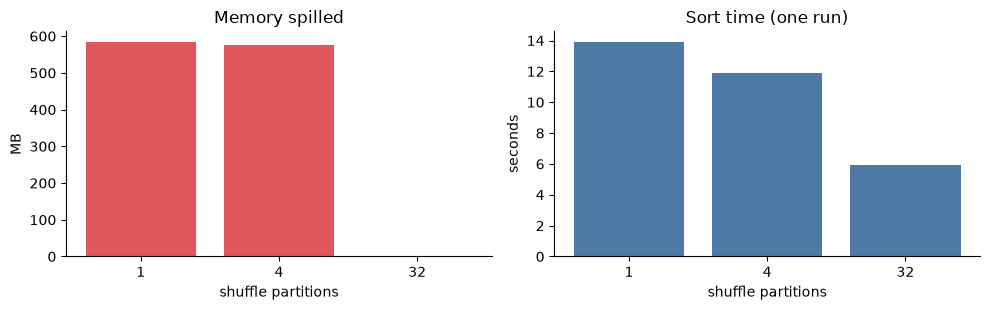

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
labels = spill["shuffle partitions"].astype(str)
ax[0].bar(labels, spill["memory spilled MB"], color="#E15759")
ax[0].set(title="Memory spilled", xlabel="shuffle partitions", ylabel="MB")
ax[1].bar(labels, spill["seconds"], color="#4E79A7")
ax[1].set(title="Sort time (one run)", xlabel="shuffle partitions", ylabel="seconds")
plt.tight_layout(); plt.show()

*Insight: With 1 and 4 shuffle partitions, the sort spilled 584 MB and 576 MB from memory (187 MB and 184 MB on disk). With 32 partitions, each task got about 10 MB of the 304 MB shuffle data, and nothing spilled. The sort took 5.9 s instead of 13.9 s. The shuffle write was 304 MB in all three runs: more partitions do not move more data, they cut it into pieces that fit in the memory of a task.*

## 4. File Format and Compression

The file format decides how much Spark must read for a query. **CSV** is text: Spark parses every byte of every
row. **Parquet** and **ORC** store each column separately, compressed, with min/max statistics per row group, so a
filter on two columns reads only those columns and can skip row groups. The cell writes January 2024 in five
format and codec combinations and runs the same filtered query on each (with an explicit schema for CSV, so there
is no schema inference).

In [6]:
jan = spark.read.parquet(JAN).coalesce(4)
print("ORC default codec in this Spark:", spark.conf.get("spark.sql.orc.compression.codec"))
formats = {
    "CSV (none)": lambda p: jan.write.option("header", True).csv(p),
    "CSV (gzip)": lambda p: jan.write.option("header", True).option("compression", "gzip").csv(p),
    "Parquet (snappy)": lambda p: jan.write.option("compression", "snappy").parquet(p),
    "Parquet (zstd)": lambda p: jan.write.option("compression", "zstd").parquet(p),
    "ORC (zstd)": lambda p: jan.write.option("compression", "zstd").orc(p),
}
schema = jan.schema
def reader(fmt: str, p: str):
    if fmt.startswith("CSV"):
        return spark.read.schema(schema).option("header", True).csv(p)
    return spark.read.parquet(p) if fmt.startswith("Parquet") else spark.read.orc(p)

def filtered(df):
    return (df.where((F.col("PULocationID") == 132) & (F.col("tip_amount") > 20))
              .agg(F.count("*").alias("trips"), F.round(F.avg("fare_amount"), 4).alias("avg_fare")).collect()[0])

def best_of(fn, n=2):
    times = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return min(times)

rows, paths = [], {}
for fmt, writer in formats.items():
    p = paths[fmt] = str(OUT / fmt.split()[0].lower() / fmt.split("(")[1].rstrip(")"))
    t0 = time.perf_counter(); writer(p); write_s = time.perf_counter() - t0
    size = sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file() and not f.name.startswith((".", "_")))
    res = filtered(reader(fmt, p))
    rows.append({"format": fmt, "size MB": mb(size), "write s": round(write_s, 1),
                 "query s": round(best_of(lambda: filtered(reader(fmt, p))), 2), "trips": res.trips, "avg fare": res.avg_fare})
fmt_df = pd.DataFrame(rows)
print(fmt_df.to_string(index=False))
print("same answer in all formats:", fmt_df[["trips", "avg fare"]].nunique().max() == 1)

ORC default codec in this Spark: zstd


          format  size MB  write s  query s  trips  avg fare
      CSV (none)      308      9.3     1.20   8080   86.7421
      CSV (gzip)       55     12.1     1.48   8080   86.7421
Parquet (snappy)       58      3.4     0.23   8080   86.7421
  Parquet (zstd)       44      2.8     0.20   8080   86.7421
      ORC (zstd)       54      3.8     0.24   8080   86.7421
same answer in all formats: True


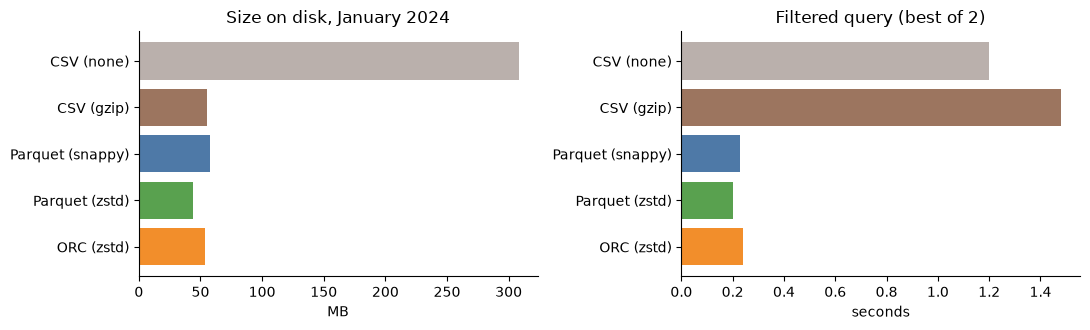

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
colors = ["#BAB0AC", "#9C755F", "#4E79A7", "#59A14F", "#F28E2B"]
ax[0].barh(fmt_df["format"], fmt_df["size MB"], color=colors)
ax[0].set(title="Size on disk, January 2024", xlabel="MB"); ax[0].invert_yaxis()
ax[1].barh(fmt_df["format"], fmt_df["query s"], color=colors)
ax[1].set(title="Filtered query (best of 2)", xlabel="seconds"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

*Insight: Parquet and ORC answered the query in 0.20 s to 0.24 s, 5x to 6x faster than plain CSV (1.20 s). With gzip, the CSV files were 5.6x smaller (55 MB instead of 308 MB), but the query took longer (1.48 s). Spark must still decompress and parse every row. Parquet with zstd was the smallest file (44 MB, against 58 MB with snappy) and also the fastest to write (2.8 s). All five formats gave the same answer: 8,080 trips with an average fare of 86.7421 $.*

## 5. Caching and Storage Levels

`cache()` keeps a DataFrame after its first computation, so the next queries skip the work that produced it.
Caching pays off when that work is expensive: parsing text, a large join, a UDF. The example caches the trips
parsed from the uncompressed CSV files of section 4. The **storage level** says where the cached blocks live.
In PySpark the levels are:

| Level | Memory | Disk | Form |
| :--- | :-: | :-: | :--- |
| `MEMORY_AND_DISK_DESER` (what `df.cache()` uses) | yes | overflow | deserialized |
| `MEMORY_ONLY` | yes | no (partitions that do not fit are recomputed) | serialized bytes |
| `MEMORY_AND_DISK` | yes | overflow | serialized bytes |
| `DISK_ONLY` | no | yes | serialized bytes |

For DataFrames, Spark always caches **column batches** (compressed per column); "serialized" adds one more
serialization step on top. The cell caches six columns with each level, reads the size from the storage endpoint,
and times the same aggregation (best of 2).

In [8]:
base = reader("CSV (none)", paths["CSV (none)"]).select(
    "tpep_pickup_datetime", "PULocationID", "DOLocationID", "trip_distance", "tip_amount", "total_amount")
query = lambda df: df.groupBy("PULocationID").agg(F.sum("total_amount"), F.avg("tip_amount")).collect()

rows = [{"level": "no cache (parse CSV)", "fill s": None, "memory MB": 0, "disk MB": 0,
         "query s": round(best_of(lambda: query(base)), 2)}]
for name in ["MEMORY_AND_DISK_DESER", "MEMORY_ONLY", "MEMORY_AND_DISK", "DISK_ONLY"]:
    df = base.persist(getattr(StorageLevel, name))
    t0 = time.perf_counter(); df.count(); fill = time.perf_counter() - t0      # count() fills the cache
    time.sleep(1)
    st = api("storage/rdd")[0]
    rows.append({"level": name, "fill s": round(fill, 1), "memory MB": mb(st["memoryUsed"]),
                 "disk MB": mb(st["diskUsed"]), "query s": round(best_of(lambda: query(df)), 2),
                 "partitions cached": f'{st["numCachedPartitions"]}/{st["numPartitions"]}'})
    df.unpersist(blocking=True)
cache = pd.DataFrame(rows)
print(cache.to_string(index=False))

                level  fill s  memory MB  disk MB  query s partitions cached
 no cache (parse CSV)     NaN          0        0     1.66               NaN
MEMORY_AND_DISK_DESER     3.3         99        0     0.17               4/4
          MEMORY_ONLY     3.1         52        0     0.19               4/4
      MEMORY_AND_DISK     3.3         52        0     0.18               4/4
            DISK_ONLY     2.7          0       52     0.15               4/4


*Insight: Every storage level cut the query time from 1.66 s to 0.15 s to 0.19 s, about 10x faster. Without a cache, Spark parses the CSV again. The default `MEMORY_AND_DISK_DESER` used 99 MB of memory; the serialized levels needed 52 MB, about half, for almost the same query time. `DISK_ONLY` was as fast as memory here (0.15 s), most likely because the operating system keeps the 52 MB file in its page cache. Filling the cache took 2.7 s to 3.3 s, so the cache pays off from the third query on.*

## 6. A Tuning Checklist

Local-mode timings are indicative: the numbers above come from one 4-core machine. The order of the checks is the
same on a cluster.

| Check | Where you see it | Typical fix |
| :--- | :--- | :--- |
| Shuffle partitions | Stages tab: task count, task size, spill | `spark.sql.shuffle.partitions`; aim for 100-200 MB of shuffle data per task; keep AQE on |
| AQE | SQL tab: `AdaptiveSparkPlan`, coalesced partitions, skew join | `spark.sql.adaptive.enabled=true` (default); `advisoryPartitionSizeInBytes` |
| Broadcast joins | SQL tab: `BroadcastHashJoin` vs. `SortMergeJoin` | `spark.sql.autoBroadcastJoinThreshold` (10 MB default); `broadcast()` hint for small tables |
| Spill | Stages tab: "Spill (Memory)", "Spill (Disk)" | more partitions, more executor memory, fewer cores per executor |
| Caching | Storage tab: size, fraction cached | cache only data that is reused; `unpersist()` when done; `MEMORY_AND_DISK` for large data |
| Skew | Stages tab: max task time far above the median | AQE skew join, salting, filter hot keys |
| File sizes | input bytes / number of tasks of the scan stage | 128 MB-1 GB files; compact small files (Delta `OPTIMIZE`) |
| File format | input bytes of the scan stage | Parquet or ORC with zstd/snappy; partition by a column that queries filter on |
| Executor sizing (cluster) | Executors tab: GC time, memory, failed tasks | about 5 cores per executor with a few GB of heap per core; `spark.executor.memoryOverhead` for Python workers and off-heap memory |
| Python UDFs | SQL tab: `BatchEvalPython` / `ArrowEvalPython` | built-in functions first, then Arrow (pandas) UDFs |

## Real-World Use Case or Analogy

The Spark UI is like the **dashboard and trip computer of a car**. You do not open the engine when the car is slow;
you look at the fuel use, the gear and the temperature first. A spill is like a desk that is too small for the
papers you work on: you put piles on the floor and pick them up again later, which works, but slowly. More shuffle
partitions give each worker a smaller pile.

Data platform teams read the same REST API in their monitoring: a scheduled job exports stage metrics (spill,
shuffle bytes, task time skew) of every production run to a dashboard. An alert fires when a job starts to spill
after the data grows, before the run time of the nightly pipeline doubles.

In [9]:
spark.stop()